# Somarathne R N N (IT25100295)
#Class Imbalance Detection and Training Only Class Balancing



## Part 1 - Install libraries

In [1]:
%pip -q install kagglehub opencv-python-headless scikit-image scikit-learn

## Part 2 - Imports/folders

In [2]:
from pathlib import Path
import os, zipfile, shutil, hashlib, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE = Path('/content') if Path('/content').exists() else Path.cwd()
WORK = BASE / 'brain_tumor_preprocessing'
DATA_DIR = WORK / 'dataset'
RESULTS = WORK / 'results'
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

## Part 3 - Download the assigned dataset from KaggleHub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sartajbhuvaji/brain-tumor-classification-mri")

print("Path to dataset files:", path)

DATASET_ROOT = Path(path)
TRAIN_DIR = DATASET_ROOT / "Training"
TEST_DIR = DATASET_ROOT / "Testing"

assert TRAIN_DIR.exists(), f"Training folder not found inside: {DATASET_ROOT}"
assert TEST_DIR.exists(), f"Testing folder not found inside: {DATASET_ROOT}"

print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)


Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Path to dataset files: /kaggle/input/brain-tumor-classification-mri
Training folder: /kaggle/input/brain-tumor-classification-mri/Training
Testing folder : /kaggle/input/brain-tumor-classification-mri/Testing


## Part 4 - Create manifests, clean data and split 80/20

In [4]:
def make_manifest(root, split_name):
    rows = []
    for class_dir in sorted([p for p in root.iterdir() if p.is_dir()]):
        for p in sorted(class_dir.rglob('*')):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({
                    'split': split_name,
                    'class_name': class_dir.name,
                    'path': str(p)
                })
    return pd.DataFrame(rows)

train_raw = make_manifest(TRAIN_DIR, 'Training')
test_raw = make_manifest(TEST_DIR, 'Testing')

print('Raw Training images:', len(train_raw))
print('Raw Testing images :', len(test_raw))
display(pd.concat({
    'Training': train_raw['class_name'].value_counts().sort_index(),
    'Testing': test_raw['class_name'].value_counts().sort_index()
}, axis=1).fillna(0).astype(int))

Raw Training images: 2870
Raw Testing images : 394


,Training,Testing
class_name,,
glioma_tumor,826,100
meningioma_tumor,822,115
no_tumor,395,105
pituitary_tumor,827,74


In [5]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def image_is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def audit_manifest(df, label):
    out = df.copy()
    out['valid'] = out['path'].map(image_is_valid)
    out['sha256'] = None
    valid_idx = out.index[out['valid']].tolist()
    for n, idx in enumerate(valid_idx, start=1):
        out.at[idx, 'sha256'] = sha256_file(out.at[idx, 'path'])
        if n % 500 == 0:
            print(f'{label}: hashed {n}/{len(valid_idx)}')
    return out

In [6]:
train_audit = audit_manifest(train_raw, 'Training')
test_audit = audit_manifest(test_raw, 'Testing')

train_valid = train_audit[train_audit['valid']].copy()
test_valid = test_audit[test_audit['valid']].copy()

# Exact duplicates inside Training: keep one copy.
train_valid['duplicate_in_training'] = train_valid.duplicated('sha256', keep='first')
duplicate_copies = train_valid[train_valid['duplicate_in_training']].copy()
train_unique = train_valid[~train_valid['duplicate_in_training']].copy()

# Exact Training <-> Testing overlap: keep official Test, remove Train copy.
test_hashes = set(test_valid['sha256'].dropna())
train_unique['overlaps_testing'] = train_unique['sha256'].isin(test_hashes)
cross_overlap = train_unique[train_unique['overlaps_testing']].copy()

train_clean = train_unique[~train_unique['overlaps_testing']].copy().reset_index(drop=True)
test_clean = test_valid.copy().reset_index(drop=True)

print('Raw Training                    :', len(train_raw))
print('Exact duplicate copies removed  :', len(duplicate_copies))
print('Unique Training after dedup      :', len(train_unique))
print('Unique Training/Test overlaps    :', len(cross_overlap))
print('Leakage-safe Training            :', len(train_clean))
print('Official Testing kept            :', len(test_clean))

Training: hashed 500/2870
Training: hashed 1000/2870
Training: hashed 1500/2870
Training: hashed 2000/2870
Training: hashed 2500/2870
Raw Training                    : 2870
Exact duplicate copies removed  : 93
Unique Training after dedup      : 2777
Unique Training/Test overlaps    : 64
Leakage-safe Training            : 2713
Official Testing kept            : 394


In [7]:
from sklearn.model_selection import train_test_split

train_80, validation_20 = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=SEED,
    stratify=train_clean['class_name']
)
train_80 = train_80.reset_index(drop=True)
validation_20 = validation_20.reset_index(drop=True)
official_test = test_clean.reset_index(drop=True)

split_counts = pd.concat({
    'Train_80': train_80['class_name'].value_counts().sort_index(),
    'Validation_20': validation_20['class_name'].value_counts().sort_index(),
    'Official_Test': official_test['class_name'].value_counts().sort_index()
}, axis=1).fillna(0).astype(int)

display(split_counts)
print('Actual Training:', len(train_80))
print('Validation     :', len(validation_20))
print('Official Test  :', len(official_test))

,Train_80,Validation_20,Official_Test
class_name,,,
glioma_tumor,654,164,100
meningioma_tumor,651,163,115
no_tumor,217,54,105
pituitary_tumor,648,162,74


Actual Training: 2170
Validation     : 543
Official Test  : 394


## Part 5 - Define common image preparation and augmentation helpers

In [8]:
TARGET_SIZE = (224, 224)
PADDING_VALUE = (0, 0, 0)

def resize_with_padding(image, target_size=TARGET_SIZE, fill=PADDING_VALUE):
    image = image.convert('RGB')
    target_w, target_h = target_size
    original_w, original_h = image.size
    scale = min(target_w / original_w, target_h / original_h)
    new_w = max(1, int(round(original_w * scale)))
    new_h = max(1, int(round(original_h * scale)))
    resized = image.resize((new_w, new_h), Image.Resampling.LANCZOS)

    pad_left = (target_w - new_w) // 2
    pad_top = (target_h - new_h) // 2
    pad_right = target_w - new_w - pad_left
    pad_bottom = target_h - new_h - pad_top

    padded = ImageOps.expand(
        resized,
        border=(pad_left, pad_top, pad_right, pad_bottom),
        fill=fill
    )
    return padded, {
        'original_width': original_w,
        'original_height': original_h,
        'resized_width': new_w,
        'resized_height': new_h,
        'pad_left': pad_left,
        'pad_right': pad_right,
        'pad_top': pad_top,
        'pad_bottom': pad_bottom,
        'final_width': padded.size[0],
        'final_height': padded.size[1],
        'scale_factor': scale,
    }

In [9]:
import cv2

CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

def apply_clahe_rgb(pil_image):
    rgb = np.asarray(pil_image.convert('RGB'), dtype=np.uint8)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)
    l2 = clahe.apply(l)
    enhanced = cv2.cvtColor(cv2.merge([l2, a, b]), cv2.COLOR_LAB2RGB)
    return Image.fromarray(enhanced)

In [10]:
def augment_pil(image, rng):
    image = image.convert('RGB')
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)

    angle = rng.uniform(-12, 12)
    image = image.rotate(
        angle,
        resample=Image.Resampling.BILINEAR,
        fillcolor=(0, 0, 0)
    )

    max_shift = 10
    shift_x = rng.randint(-max_shift, max_shift)
    shift_y = rng.randint(-max_shift, max_shift)
    image = image.transform(
        image.size,
        Image.Transform.AFFINE,
        (1, 0, shift_x, 0, 1, shift_y),
        resample=Image.Resampling.BILINEAR,
        fillcolor=(0, 0, 0)
    )

    image = ImageEnhance.Brightness(image).enhance(rng.uniform(0.90, 1.10))
    image = ImageEnhance.Contrast(image).enhance(rng.uniform(0.90, 1.10))
    return image

## Part 6 - EDA BEFORE balancing: detect class imbalance

,images
class_name,
glioma_tumor,654
meningioma_tumor,651
no_tumor,217
pituitary_tumor,648


Largest/smallest class ratio: 3.014


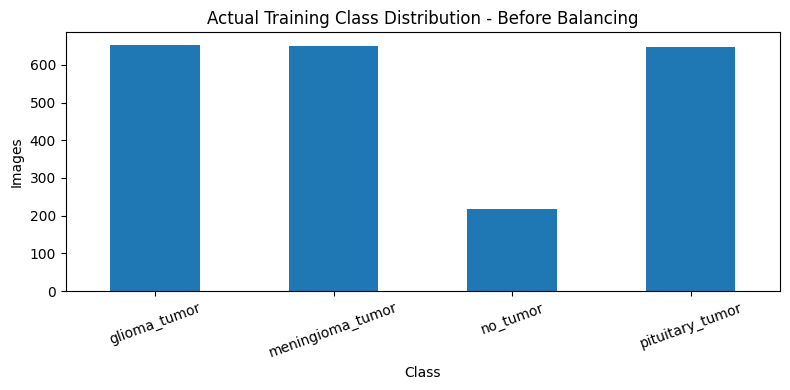

In [11]:
before_balance=train_80['class_name'].value_counts().sort_index()
display(before_balance.to_frame('images'))
imbalance_ratio=float(before_balance.max()/before_balance.min())
print('Largest/smallest class ratio:',round(imbalance_ratio,3))
plt.figure(figsize=(8,4)); before_balance.plot(kind='bar')
plt.title('Actual Training Class Distribution - Before Balancing')
plt.xlabel('Class'); plt.ylabel('Images'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## Part 7 - Set the balancing target from the largest Training class

In [12]:
target_count=int(before_balance.max())
needed=(target_count-before_balance).astype(int)
print('Target per class:',target_count)
display(pd.DataFrame({'current':before_balance,'extra_needed':needed}))

Target per class: 654


,current,extra_needed
class_name,,
glioma_tumor,654,0
meningioma_tumor,651,3
no_tumor,217,437
pituitary_tumor,648,6


## Part 8 - Create targeted augmented samples only where needed

In [13]:
OUT=RESULTS/'member5_class_balancing'
BAL_ROOT=OUT/'balanced_training_dataset'
OUT.mkdir(parents=True,exist_ok=True)
records=[]
classes=sorted(train_80['class_name'].unique())

for class_idx,class_name in enumerate(classes):
    class_df=train_80[train_80['class_name']==class_name].reset_index(drop=True)
    dst_dir=BAL_ROOT/class_name
    dst_dir.mkdir(parents=True,exist_ok=True)
    prepared=[]

    for _,row in class_df.iterrows():
        src=Path(row['path'])
        with Image.open(src) as im:
            img,_=resize_with_padding(im)
        img=apply_clahe_rgb(img)
        dst=dst_dir/f'{src.stem}_original.png'
        img.save(dst)
        prepared.append((src,img))
        records.append({'class_name':class_name,'type':'original','source_path':str(src),'output_path':str(dst)})

    extra=target_count-len(prepared)
    for j in range(extra):
        src,img=prepared[j%len(prepared)]
        rng=random.Random(SEED+(class_idx+1)*100000+j)
        aug=augment_pil(img,rng)
        dst=dst_dir/f'{src.stem}_balance_aug_{j+1:04d}.png'
        aug.save(dst)
        records.append({'class_name':class_name,'type':'balance_augmented','source_path':str(src),'output_path':str(dst)})
    print(class_name,'original=',len(prepared),'added=',extra,'final=',target_count)

balance_report=pd.DataFrame(records)
balance_report.to_csv(OUT/'class_balancing_report.csv',index=False)

glioma_tumor original= 654 added= 0 final= 654
meningioma_tumor original= 651 added= 3 final= 654
no_tumor original= 217 added= 437 final= 654
pituitary_tumor original= 648 added= 6 final= 654


## Part 9 - EDA AFTER balancing: compare class counts

,Before,After
class_name,,
glioma_tumor,654,654
meningioma_tumor,651,654
no_tumor,217,654
pituitary_tumor,648,654


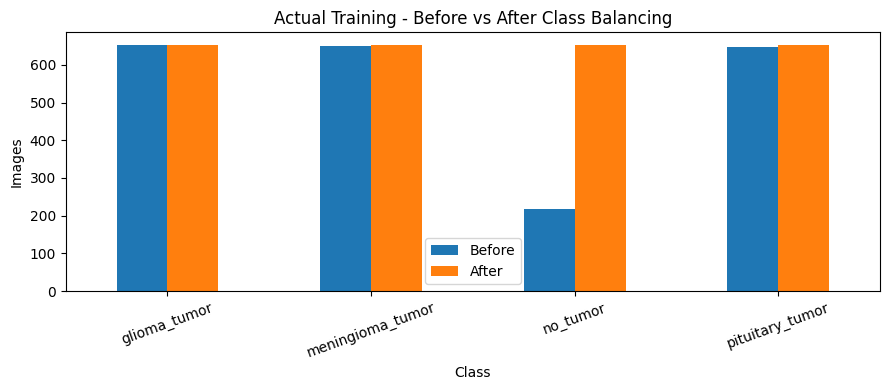

Validation remains unchanged: 543
Official Test remains unchanged: 394


In [14]:
after_balance=balance_report['class_name'].value_counts().sort_index()
comparison=pd.concat([before_balance.rename('Before'),after_balance.rename('After')],axis=1)
display(comparison)
comparison.plot(kind='bar',figsize=(9,4))
plt.title('Actual Training - Before vs After Class Balancing')
plt.xlabel('Class'); plt.ylabel('Images'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print('Validation remains unchanged:',len(validation_20))
print('Official Test remains unchanged:',len(official_test))

## Part 10 - Download Member 5 outputs

In [15]:
def make_zip(folder, zip_path):
    folder = Path(folder)
    zip_path = Path(zip_path)
    if zip_path.exists():
        zip_path.unlink()
    shutil.make_archive(str(zip_path.with_suffix('')), 'zip', root_dir=folder)
    return zip_path

def download_file(path):
    try:
        from google.colab import files
        files.download(str(path))
    except Exception:
        print('Saved at:', path)

In [16]:
ZIP_OUT=make_zip(OUT,RESULTS/'Member5_Class_Balancing_Outputs.zip')
print('Created:',ZIP_OUT)
download_file(ZIP_OUT)

Created: /content/brain_tumor_preprocessing/results/Member5_Class_Balancing_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>